In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import pandas as pd
import os
# --- IMPORTANT: Replace this with the actual path to your CSV file in Google Drive ---
# Example: If you exported 'Impact of Social Media & FOMO on Online Buying Behavior Among Gen-Z (Responses).gsheet'
# as a CSV and uploaded it to your MyDrive, its path might be like:
# csv_file_path = '/content/drive/MyDrive/Impact of Social Media & FOMO on Online Buying Behavior Among Gen-Z (Responses).csv'

csv_file_path = '/content/drive/MyDrive/ML/HR-Employee-Attrition.csv' # <<<--- UPDATE THIS PATH


# Try to read the CSV file
try:
    if os.path.exists(csv_file_path):
        df = pd.read_csv(csv_file_path, encoding='latin1')
        print(f"Successfully loaded '{csv_file_path}'.")
        display(df.head())
    else:
        print(f"Error: The file '{csv_file_path}' was not found. Please ensure the path is correct and the file exists.")
        print("Remember, a .gsheet file needs to be exported as a .csv first from Google Sheets.")
except Exception as e:
    print(f"An error occurred while reading the CSV file: {e}")

Successfully loaded '/content/drive/MyDrive/ML/HR-Employee-Attrition.csv'.


,ï»¿Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [5]:
print('Descriptive Statistics:')
display(df.describe())

Descriptive Statistics:


,ï»¿Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


### Descriptive Statistics with Skewness and Kurtosis

In [6]:
numerical_df = df.select_dtypes(include=['number'])

descriptive_stats = numerical_df.describe()
skewness = numerical_df.skew()
kurtosis = numerical_df.kurt()

# Combine into a single DataFrame for better presentation
extended_stats = pd.DataFrame({
    'skew': skewness,
    'kurt': kurtosis
}).T # Transpose to align with describe() output

full_stats = pd.concat([descriptive_stats, extended_stats])

print('Descriptive Statistics (including Skewness and Kurtosis):')
display(full_stats)

Descriptive Statistics (including Skewness and Kurtosis):


,ï»¿Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000
skew,0.413286,-0.003519,0.958118,-0.289681,0.0,0.016574,-0.321654,-0.032311,-0.498419,1.025401,...,-0.302828,0.0,0.968980,1.117172,0.553124,-0.552480,1.764529,0.917363,1.984290,0.833451
kurt,-0.404145,-1.203823,-0.224833,-0.559115,0.0,-1.223179,-1.202521,-1.196398,0.270999,0.399152,...,-1.184814,0.0,0.364634,0.918270,0.494993,0.419460,3.935509,0.477421,3.612673,0.171058


### Distribution of 'YearsAtCompany'

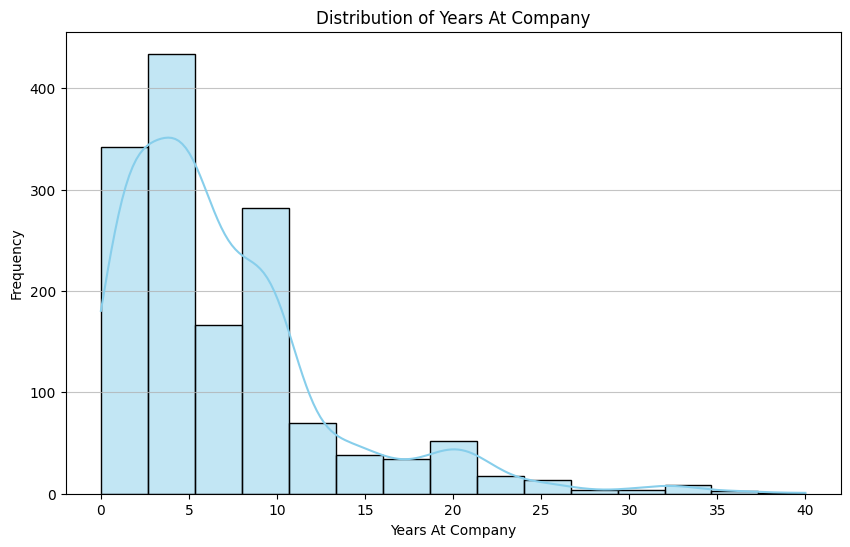

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.histplot(df['YearsAtCompany'], bins=15, kde=True, color='skyblue')
plt.title('Distribution of Years At Company')
plt.xlabel('Years At Company')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.75)
plt.show()

### Distribution of 'DistanceFromHome'

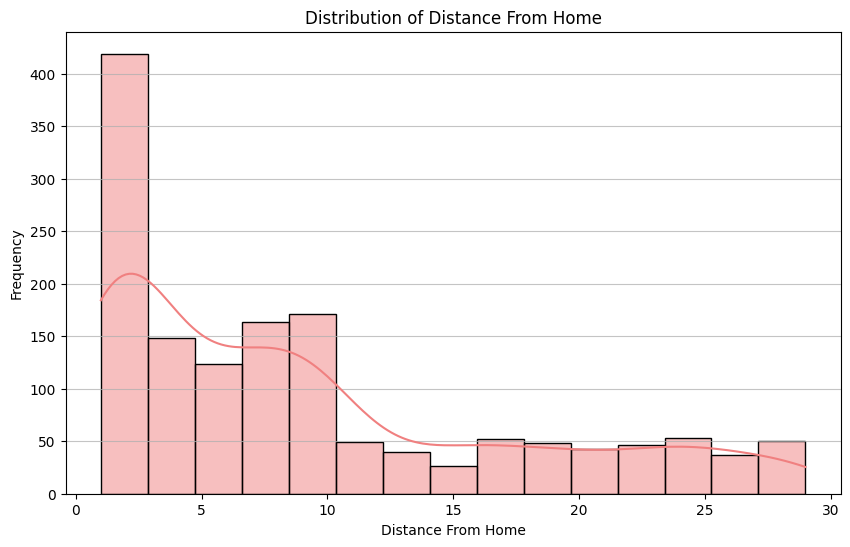

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.histplot(df['DistanceFromHome'], bins=15, kde=True, color='lightcoral')
plt.title('Distribution of Distance From Home')
plt.xlabel('Distance From Home')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.75)
plt.show()

### Distribution of 'NumCompaniesWorked'

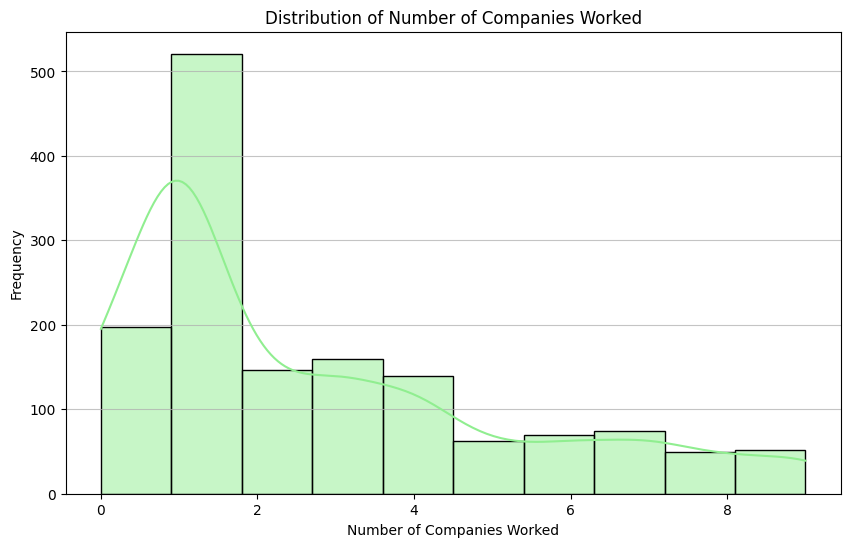

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.histplot(df['NumCompaniesWorked'], bins=10, kde=True, color='lightgreen')
plt.title('Distribution of Number of Companies Worked')
plt.xlabel('Number of Companies Worked')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.75)
plt.show()

### Boxplot for 'YearsAtCompany' to Identify Outliers

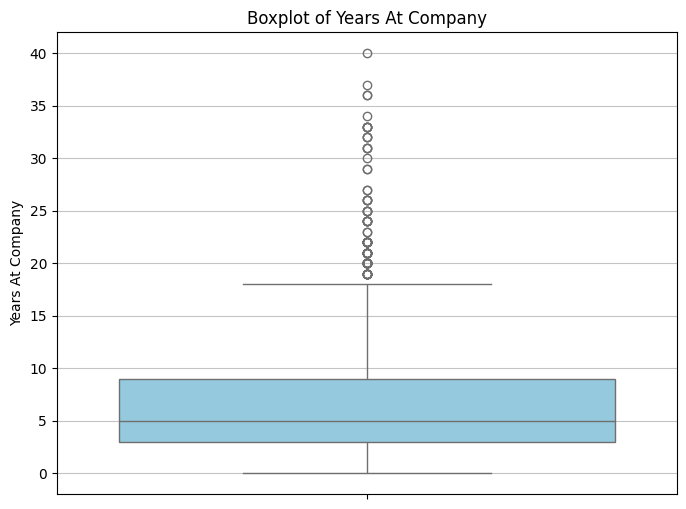

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.boxplot(y=df['YearsAtCompany'], color='skyblue')
plt.title('Boxplot of Years At Company')
plt.ylabel('Years At Company')
plt.grid(axis='y', alpha=0.75)
plt.show()

### Boxplot for 'DistanceFromHome' to Identify Outliers

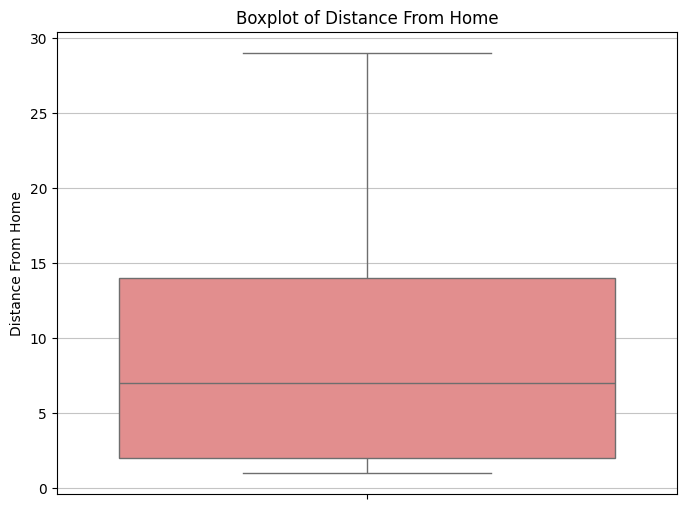

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.boxplot(y=df['DistanceFromHome'], color='lightcoral')
plt.title('Boxplot of Distance From Home')
plt.ylabel('Distance From Home')
plt.grid(axis='y', alpha=0.75)
plt.show()

### Boxplot for 'NumCompaniesWorked' to Identify Outliers

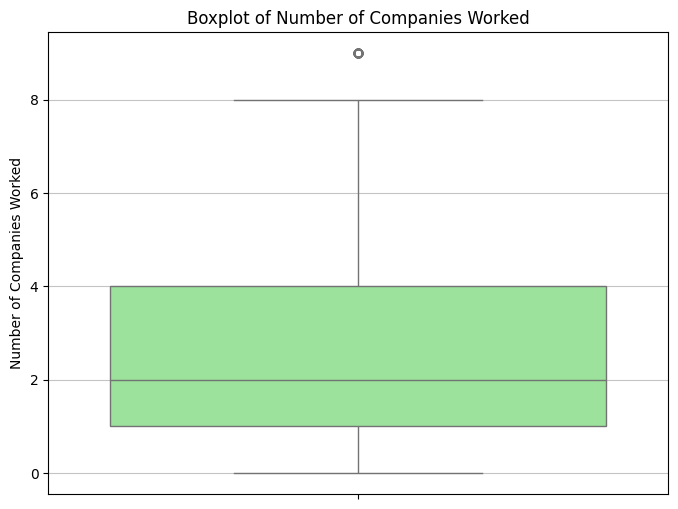

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.boxplot(y=df['NumCompaniesWorked'], color='lightgreen')
plt.title('Boxplot of Number of Companies Worked')
plt.ylabel('Number of Companies Worked')
plt.grid(axis='y', alpha=0.75)
plt.show()

### Frequency Distribution of Categorical Variables

In [14]:
categorical_vars = ['BusinessTravel', 'Department', 'Gender', 'MaritalStatus', 'OverTime', 'JobRole', 'Attrition']

for col in categorical_vars:
    print(f"\nFrequency distribution for '{col}':")
    freq_dist = df[col].value_counts().reset_index()
    freq_dist.columns = [col, 'Count']
    freq_dist['Percentage'] = (freq_dist['Count'] / freq_dist['Count'].sum()) * 100
    display(freq_dist)



Frequency distribution for 'BusinessTravel':


,BusinessTravel,Count,Percentage
0,Travel_Rarely,1043,70.952381
1,Travel_Frequently,277,18.843537
2,Non-Travel,150,10.204082



Frequency distribution for 'Department':


,Department,Count,Percentage
0,Research & Development,961,65.374150
1,Sales,446,30.340136
2,Human Resources,63,4.285714



Frequency distribution for 'Gender':


...

,OverTime,Count,Percentage
0,No,1054,71.70068
1,Yes,416,28.29932



Frequency distribution for 'JobRole':


,JobRole,Count,Percentage
0,Sales Executive,326,22.176871
1,Research Scientist,292,19.863946
2,Laboratory Technician,259,17.619048
3,Manufacturing Director,145,9.863946
4,Healthcare Representative,131,8.911565
5,Manager,102,6.938776
6,Sales Representative,83,5.646259
7,Research Director,80,5.442177
8,Human Resources,52,3.537415



Frequency distribution for 'Attrition':


,Attrition,Count,Percentage
0,No,1233,83.877551
1,Yes,237,16.122449


### Attrition Rate by Job Role

/tmp/ipykernel_2594/1732085773.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=attrition_by_jobrole.index, y=attrition_by_jobrole['AttritionRate'], palette='viridis')


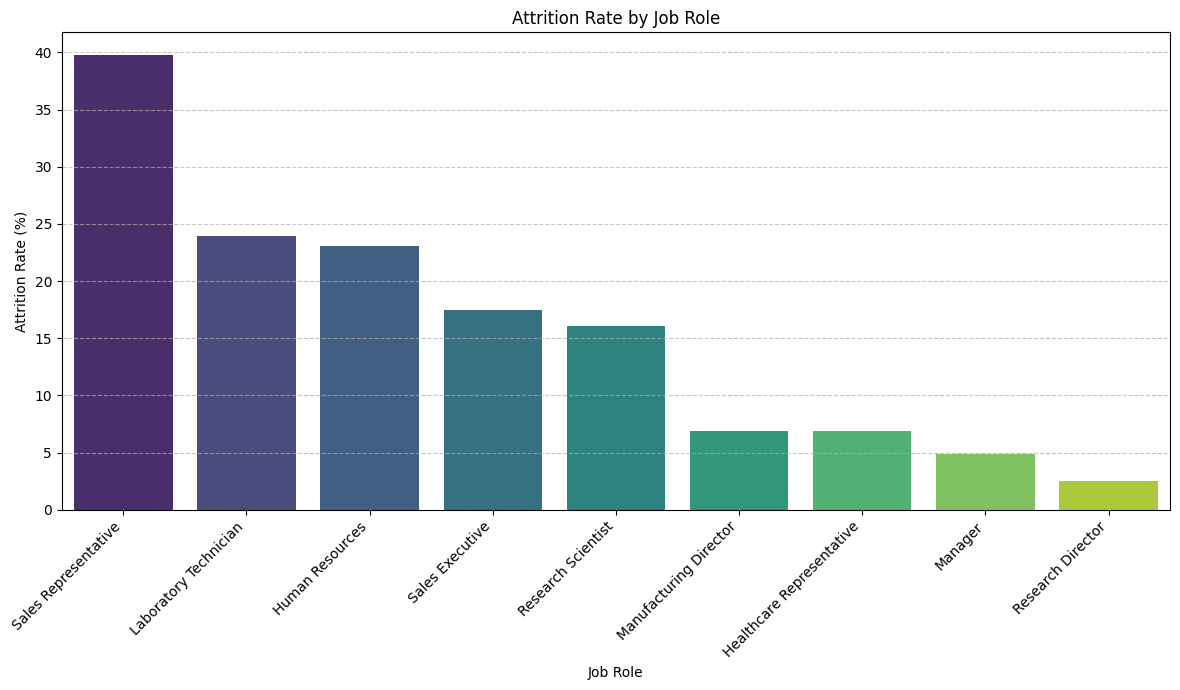

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate attrition rate by JobRole
attrition_by_jobrole = df.groupby(['JobRole', 'Attrition']).size().unstack(fill_value=0)
attrition_by_jobrole['Total'] = attrition_by_jobrole['No'] + attrition_by_jobrole['Yes']
attrition_by_jobrole['AttritionRate'] = (attrition_by_jobrole['Yes'] / attrition_by_jobrole['Total']) * 100

# Sort by attrition rate for better visualization
attrition_by_jobrole = attrition_by_jobrole.sort_values(by='AttritionRate', ascending=False)

plt.figure(figsize=(12, 7))
sns.barplot(x=attrition_by_jobrole.index, y=attrition_by_jobrole['AttritionRate'], palette='viridis')
plt.title('Attrition Rate by Job Role')
plt.xlabel('Job Role')
plt.ylabel('Attrition Rate (%)')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Attrition Rate by OverTime

/tmp/ipykernel_2594/3074361626.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=attrition_by_overtime.index, y=attrition_by_overtime['AttritionRate'], palette='coolwarm')


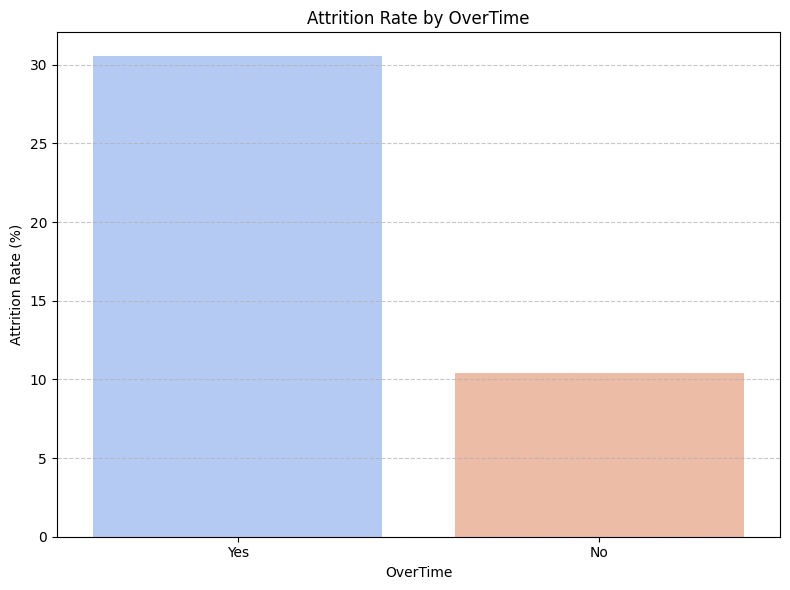

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate attrition rate by OverTime
attrition_by_overtime = df.groupby(['OverTime', 'Attrition']).size().unstack(fill_value=0)
attrition_by_overtime['Total'] = attrition_by_overtime['No'] + attrition_by_overtime['Yes']
attrition_by_overtime['AttritionRate'] = (attrition_by_overtime['Yes'] / attrition_by_overtime['Total']) * 100

# Sort by attrition rate for better visualization (Yes/No)
attrition_by_overtime = attrition_by_overtime.sort_values(by='AttritionRate', ascending=False)

plt.figure(figsize=(8, 6))
sns.barplot(x=attrition_by_overtime.index, y=attrition_by_overtime['AttritionRate'], palette='coolwarm')
plt.title('Attrition Rate by OverTime')
plt.xlabel('OverTime')
plt.ylabel('Attrition Rate (%)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


### Correlation Heatmap of Numerical Variables

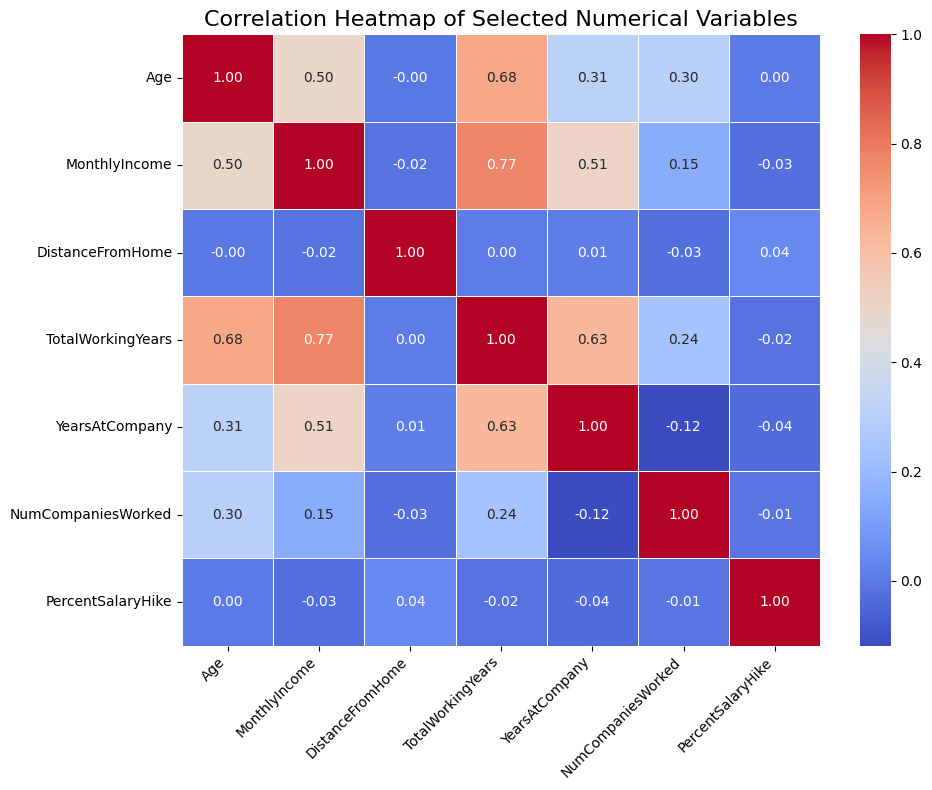

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

# Clean column names by removing any potential Byte Order Mark (BOM) or other hidden characters
df.columns = [col.replace('ï»¿', '') for col in df.columns]

# Select only the specified numerical columns for correlation calculation
specific_numerical_vars = ['Age', 'MonthlyIncome', 'DistanceFromHome', 'TotalWorkingYears', 'YearsAtCompany', 'NumCompaniesWorked', 'PercentSalaryHike']
numerical_df_subset = df[specific_numerical_vars]

# Calculate the correlation matrix
corr_matrix_subset = numerical_df_subset.corr()

# Set up the matplotlib figure
plt.figure(figsize=(10, 8))

# Draw the heatmap with the mask and correct aspect ratio
sns.heatmap(corr_matrix_subset, annot=True, cmap='coolwarm', fmt='.2f', linewidths=.5)
plt.title('Correlation Heatmap of Selected Numerical Variables', fontsize=16)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


## Logistic Regression for Attrition Prediction

In [20]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import numpy as np

# Define the features (X) and the target (y)
X = df[['Age', 'BusinessTravel', 'Department', 'DistanceFromHome', 'Education', 'EducationField',
        'EnvironmentSatisfaction', 'Gender', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction',
        'MaritalStatus', 'MonthlyIncome', 'NumCompaniesWorked', 'OverTime', 'PercentSalaryHike',
        'TotalWorkingYears', 'YearsAtCompany', 'YearsSinceLastPromotion', 'EmployeeCount', 'Over18', 'StandardHours']]
y = df['Attrition']

# Identify categorical and numerical columns in X
categorical_features = X.select_dtypes(include=['object']).columns
numerical_features = X.select_dtypes(include=np.number).columns

# Create a column transformer for preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ])

# Create a pipeline with preprocessing and logistic regression
model_pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                               ('classifier', LogisticRegression(solver='liblinear', random_state=42))])

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Train the logistic regression model
model_pipeline.fit(X_train, y_train)

print("Model training complete.")


Model training complete.


### Model Evaluation

In [21]:
# Make predictions on the test set
y_pred = model_pipeline.predict(X_test)

# Evaluate the model
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print("\nConfusion Matrix:")
display(pd.DataFrame(confusion_matrix(y_test, y_pred),
                   index=['Actual No Attrition', 'Actual Attrition'],
                   columns=['Predicted No Attrition', 'Predicted Attrition']))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Accuracy: 0.8810

Confusion Matrix:


,Predicted No Attrition,Predicted Attrition
Actual No Attrition,242,5
Actual Attrition,30,17



Classification Report:
              precision    recall  f1-score   support

          No       0.89      0.98      0.93       247
         Yes       0.77      0.36      0.49        47

    accuracy                           0.88       294
   macro avg       0.83      0.67      0.71       294
weighted avg       0.87      0.88      0.86       294



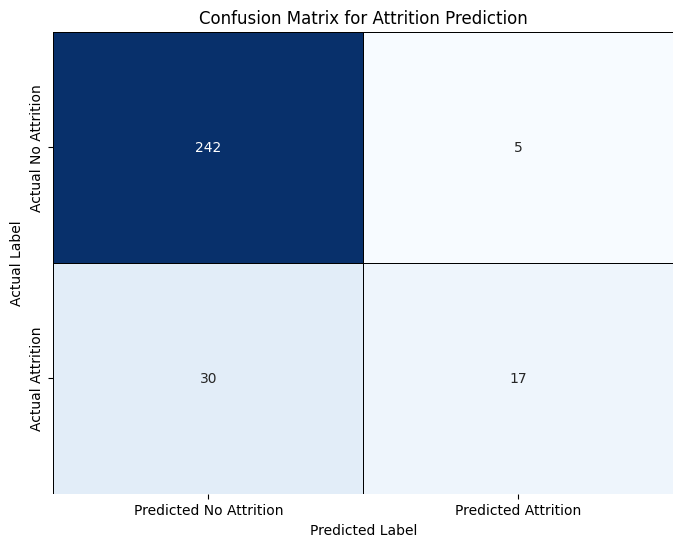

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.metrics import confusion_matrix

# Recalculate confusion matrix (or use the one from previous cell if available in the scope)
cm = confusion_matrix(y_test, y_pred)

# Create a DataFrame for better labeling
cm_df = pd.DataFrame(cm,
                     index=['Actual No Attrition', 'Actual Attrition'],
                     columns=['Predicted No Attrition', 'Predicted Attrition'])

plt.figure(figsize=(8, 6))
sns.heatmap(cm_df, annot=True, fmt='d', cmap='Blues', cbar=False,
            linewidths=.5, linecolor='black')
plt.title('Confusion Matrix for Attrition Prediction')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()
